In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report)
import seaborn as sns
import time

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)


TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

class_names = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
               'Dog', 'Frog', 'Horse', 'Ship', 'Truck']

# Normalize pixel values to [0, 1] for display / general use (Task 1 requirement)
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# NOTE: keep a raw 0-255 copy for the VGG16 branch below.
# VGG16's preprocess_input does ITS OWN scaling (channel-mean subtraction expecting
# 0-255 input). Feeding it already-[0,1]-normalized data double-normalizes the pixels
# and collapses the model to predicting a single class (this was the "all predictions
# = Ship" bug). So the model in Task 2 rebuilds the 0-255 scale internally.

# One-hot encode labels
y_train_cat = to_categorical(y_train, num_classes=10)
y_test_cat = to_categorical(y_test, num_classes=10)

print("Training data shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing data shape:", x_test.shape)
print("Testing labels shape:", y_test.shape)


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1201s 7us/step
Training data shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Testing data shape: (10000, 32, 32, 3)
Testing labels shape: (10000, 1)


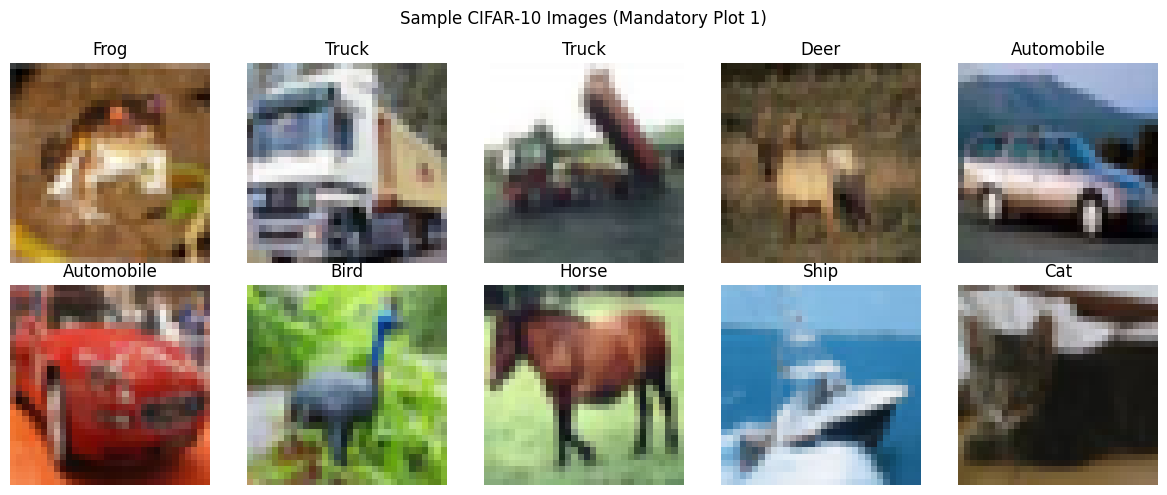

In [3]:
# Display 10 sample images
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis('off')
plt.suptitle("Sample CIFAR-10 Images (Mandatory Plot 1)")
plt.tight_layout()
plt.savefig('sample_cifar10_images.png', dpi=150, bbox_inches='tight')
plt.show()


In [4]:
# Quick numeric parameter comparison (for the report table in Section 8)
import pandas as pd

comparison_df = pd.DataFrame({
    'Model': ['LeNet-5', 'AlexNet', 'VGG16', 'GoogleNet', 'ResNet50'],
    'Depth': [7, 8, 16, 22, 50],
    'Parameters': ['60K', '61M', '138M', '6.8M', '25.6M'],
    'Main Contribution': ['First CNN', 'ReLU + Dropout', 'Deep 3x3 filters',
                           'Inception Modules', 'Residual Learning']
})
print(comparison_df.to_string(index=False))


    Model  Depth Parameters Main Contribution
  LeNet-5      7        60K         First CNN
  AlexNet      8        61M    ReLU + Dropout
    VGG16     16       138M  Deep 3x3 filters
GoogleNet     22       6.8M Inception Modules
 ResNet50     50      25.6M Residual Learning


In [5]:
IMG_SIZE = 64  # resized input for VGG16 (32x32 is technically usable with VGG16 but 64x64 works better)

def build_transfer_model(base_trainable=False, dense_units=256, dropout=0.3):
    base_model = VGG16(weights='imagenet', include_top=False,
                        input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base_model.trainable = base_trainable  # Freeze convolutional base

    inputs = keras.Input(shape=(32, 32, 3))          # expects [0,1]-normalized input
    x = layers.Rescaling(255.0)(inputs)               # undo the /255 -> back to [0,255]
    x = layers.Resizing(IMG_SIZE, IMG_SIZE)(x)
    x = layers.Lambda(preprocess_input)(x)            # VGG16-specific preprocessing (expects 0-255)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)           # Global Average Pooling
    x = layers.Dense(dense_units, activation='relu')(x)  # Dense layer, ReLU
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(10, activation='softmax')(x)  # Output layer, Softmax

    model = keras.Model(inputs, outputs)
    return model, base_model

model, base_model = build_transfer_model(base_trainable=False)
model.summary()


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 2, 2, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,586 (56.64 MB)

 Trainable params: 133,898 (523.04 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [6]:
print("Total parameters:    ", model.count_params())
print("Trainable parameters:", sum(w.numpy().size for w in model.trainable_weights))
print("Frozen (non-trainable) parameters:",
      sum(w.numpy().size for w in model.non_trainable_weights))


Total parameters:     14848586
Trainable parameters: 133898
Frozen (non-trainable) parameters: 14714688


In [7]:
model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

EPOCHS_INITIAL = 15
BATCH_SIZE = 32

start_time = time.time()
history = model.fit(
    x_train, y_train_cat,
    validation_data=(x_test, y_test_cat),
    epochs=EPOCHS_INITIAL,
    batch_size=BATCH_SIZE,
    verbose=1
)
training_time_initial = time.time() - start_time
print(f"\nInitial training time: {training_time_initial:.2f} seconds")


Epoch 1/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 44s 24ms/step - accuracy: 0.6543 - loss: 1.2828 - val_accuracy: 0.7317 - val_loss: 0.7883
Epoch 2/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 34s 22ms/step - accuracy: 0.7406 - loss: 0.7607 - val_accuracy: 0.7426 - val_loss: 0.7544
Epoch 3/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 35s 22ms/step - accuracy: 0.7627 - loss: 0.6889 - val_accuracy: 0.7517 - val_loss: 0.7343
Epoch 4/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 36s 23ms/step - accuracy: 0.7780 - loss: 0.6417 - val_accuracy: 0.7579 - val_loss: 0.7410
Epoch 5/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 37s 24ms/step - accuracy: 0.7942 - loss: 0.5933 - val_accuracy: 0.7563 - val_loss: 0.7634
Epoch 6/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 38s 24ms/step - accuracy: 0.8037 - loss: 0.5633 - val_accuracy: 0.7580 - val_loss: 0.7759
Epoch 7/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 37s 24ms/step - accuracy: 0.8137 - loss: 0.5322 - val_accuracy: 0.7618 - val_loss: 0.7757
Epoch 8/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 38s 24ms/step - accuracy: 0.8226 -

In [8]:
# Record pre-fine-tuning test accuracy
pre_ft_loss, pre_ft_acc = model.evaluate(x_test, y_test_cat, verbose=0)
print(f"Test accuracy BEFORE fine-tuning: {pre_ft_acc:.4f}")

# Unfreeze the last convolutional block of VGG16 (block5_*)
base_model.trainable = True
for layer in base_model.layers:
    if layer.name.startswith('block5'):
        layer.trainable = True
    else:
        layer.trainable = False

# Recompile with a much smaller learning rate for fine-tuning
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

EPOCHS_FINETUNE = 8
start_time = time.time()
history_ft = model.fit(
    x_train, y_train_cat,
    validation_data=(x_test, y_test_cat),
    epochs=EPOCHS_FINETUNE,
    batch_size=BATCH_SIZE,
    verbose=1
)
training_time_finetune = time.time() - start_time
print(f"\nFine-tuning time: {training_time_finetune:.2f} seconds")


Test accuracy BEFORE fine-tuning: 0.7559
Epoch 1/8
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 72s 43ms/step - accuracy: 0.8739 - loss: 0.3664 - val_accuracy: 0.7887 - val_loss: 0.8619
Epoch 2/8
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 61s 39ms/step - accuracy: 0.9086 - loss: 0.2557 - val_accuracy: 0.8003 - val_loss: 0.8403
Epoch 3/8
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 60s 39ms/step - accuracy: 0.9264 - loss: 0.2031 - val_accuracy: 0.8070 - val_loss: 0.8739
Epoch 4/8
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 60s 39ms/step - accuracy: 0.9406 - loss: 0.1614 - val_accuracy: 0.8178 - val_loss: 0.8690
Epoch 5/8
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 60s 39ms/step - accuracy: 0.9488 - loss: 0.1403 - val_accuracy: 0.8224 - val_loss: 0.8707
Epoch 6/8
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 61s 39ms/step - accuracy: 0.9576 - loss: 0.1182 - val_accuracy: 0.8280 - val_loss: 0.8375
Epoch 7/8
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 61s 39ms/step - accuracy: 0.9618 - loss: 0.1066 - val_accuracy: 0.8320 - val_loss: 0.8638
Epoch 8/8
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6

In [9]:
post_ft_loss, post_ft_acc = model.evaluate(x_test, y_test_cat, verbose=0)
print(f"Test accuracy BEFORE fine-tuning: {pre_ft_acc:.4f}")
print(f"Test accuracy AFTER  fine-tuning: {post_ft_acc:.4f}")
print(f"Improvement: {(post_ft_acc - pre_ft_acc) * 100:.2f} percentage points")

# Combine histories for full-run plots
full_acc = history.history['accuracy'] + history_ft.history['accuracy']
full_val_acc = history.history['val_accuracy'] + history_ft.history['val_accuracy']
full_loss = history.history['loss'] + history_ft.history['loss']
full_val_loss = history.history['val_loss'] + history_ft.history['val_loss']


Test accuracy BEFORE fine-tuning: 0.7559
Test accuracy AFTER  fine-tuning: 0.8339
Improvement: 7.80 percentage points


In [10]:
y_pred_probs = model.predict(x_test, batch_size=64, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = y_test.flatten()

acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, average='macro')
rec = recall_score(y_true, y_pred, average='macro')
f1 = f1_score(y_true, y_pred, average='macro')

print(f"Test Accuracy : {acc:.4f}")
print(f"Precision (macro): {prec:.4f}")
print(f"Recall (macro)   : {rec:.4f}")
print(f"F1-score (macro) : {f1:.4f}")
print(f"Total Parameters : {model.count_params():,}")
print(f"Total Training Time (initial + fine-tune): "
      f"{training_time_initial + training_time_finetune:.2f} seconds")

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))


157/157 ━━━━━━━━━━━━━━━━━━━━ 11s 42ms/step
Test Accuracy : 0.8339
Precision (macro): 0.8336
Recall (macro)   : 0.8339
F1-score (macro) : 0.8334
Total Parameters : 14,848,586
Total Training Time (initial + fine-tune): 1062.42 seconds

Classification Report:

              precision    recall  f1-score   support

    Airplane       0.85      0.87      0.86      1000
  Automobile       0.94      0.89      0.92      1000
        Bird       0.81      0.79      0.80      1000
         Cat       0.70      0.69      0.69      1000
        Deer       0.81      0.76      0.78      1000
         Dog       0.77      0.76      0.76      1000
        Frog       0.84      0.87      0.85      1000
       Horse       0.84      0.88      0.86      1000
        Ship       0.91      0.91      0.91      1000
       Truck       0.88      0.93      0.90      1000

    accuracy                           0.83     10000
   macro avg       0.83      0.83      0.83     10000
weighted avg       0.83      0.83     

In [11]:
def quick_train_eval(learning_rate=0.001, batch_size=32, epochs=3,
                      optimizer_name='adam', dense_units=256, freeze_all=True):
    m, bm = build_transfer_model(base_trainable=not freeze_all, dense_units=dense_units)
    if not freeze_all:
        for layer in bm.layers:
            layer.trainable = layer.name.startswith('block5')

    opt = (optimizers.Adam(learning_rate=learning_rate) if optimizer_name == 'adam'
           else optimizers.SGD(learning_rate=learning_rate, momentum=0.9))

    m.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

    t0 = time.time()
    h = m.fit(x_train, y_train_cat, validation_data=(x_test, y_test_cat),
              epochs=epochs, batch_size=batch_size, verbose=0)
    elapsed = time.time() - t0

    val_acc = h.history['val_accuracy'][-1]
    return val_acc, elapsed

configs = [
    {'learning_rate': 0.001,  'batch_size': 32, 'optimizer_name': 'adam', 'dense_units': 256, 'freeze_all': True},
    {'learning_rate': 0.0001, 'batch_size': 32, 'optimizer_name': 'adam', 'dense_units': 256, 'freeze_all': True},
    {'learning_rate': 0.001,  'batch_size': 16, 'optimizer_name': 'adam', 'dense_units': 256, 'freeze_all': True},
    {'learning_rate': 0.001,  'batch_size': 64, 'optimizer_name': 'adam', 'dense_units': 256, 'freeze_all': True},
    {'learning_rate': 0.001,  'batch_size': 32, 'optimizer_name': 'sgd',  'dense_units': 256, 'freeze_all': True},
    {'learning_rate': 0.001,  'batch_size': 32, 'optimizer_name': 'adam', 'dense_units': 128, 'freeze_all': True},
    {'learning_rate': 0.001,  'batch_size': 32, 'optimizer_name': 'adam', 'dense_units': 256, 'freeze_all': False},
]

results = []
for cfg in configs:
    val_acc, elapsed = quick_train_eval(epochs=3, **cfg)
    results.append({**cfg, 'val_accuracy': val_acc, 'time_sec': elapsed})
    print(cfg, "-> val_acc:", round(val_acc, 4), " time:", round(elapsed, 1), "s")

hp_df = pd.DataFrame(results)
hp_df


{'learning_rate': 0.001, 'batch_size': 32, 'optimizer_name': 'adam', 'dense_units': 256, 'freeze_all': True} -> val_acc: 0.7576  time: 119.5 s
{'learning_rate': 0.0001, 'batch_size': 32, 'optimizer_name': 'adam', 'dense_units': 256, 'freeze_all': True} -> val_acc: 0.7191  time: 119.8 s
{'learning_rate': 0.001, 'batch_size': 16, 'optimizer_name': 'adam', 'dense_units': 256, 'freeze_all': True} -> val_acc: 0.746  time: 134.1 s
{'learning_rate': 0.001, 'batch_size': 64, 'optimizer_name': 'adam', 'dense_units': 256, 'freeze_all': True} -> val_acc: 0.7555  time: 108.9 s
{'learning_rate': 0.001, 'batch_size': 32, 'optimizer_name': 'sgd', 'dense_units': 256, 'freeze_all': True} -> val_acc: 0.7434  time: 158.9 s
{'learning_rate': 0.001, 'batch_size': 32, 'optimizer_name': 'adam', 'dense_units': 128, 'freeze_all': True} -> val_acc: 0.7515  time: 119.3 s
{'learning_rate': 0.001, 'batch_size': 32, 'optimizer_name': 'adam', 'dense_units': 256, 'freeze_all': False} -> val_acc: 0.1  time: 186.6 s


,learning_rate,batch_size,optimizer_name,dense_units,freeze_all,val_accuracy,time_sec
0,0.0010,32,adam,256,True,0.7576,119.490294
1,0.0001,32,adam,256,True,0.7191,119.763239
2,0.0010,16,adam,256,True,0.7460,134.066997
3,0.0010,64,adam,256,True,0.7555,108.889192
4,0.0010,32,sgd,256,True,0.7434,158.879840
5,0.0010,32,adam,128,True,0.7515,119.298927
6,0.0010,32,adam,256,False,0.1000,186.613842


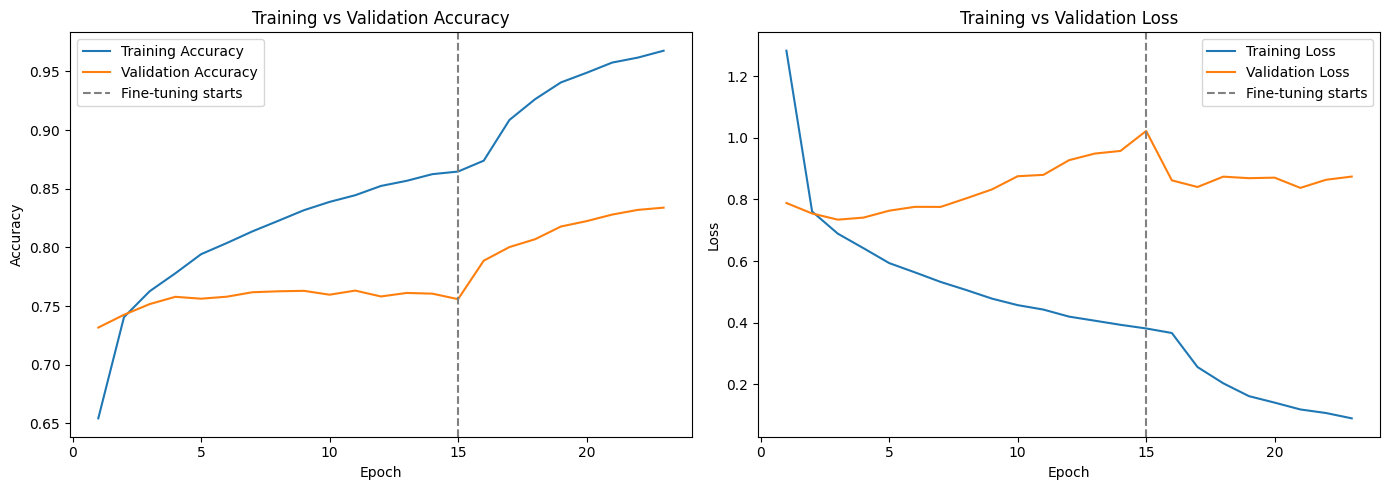

In [12]:
epochs_range = range(1, len(full_acc) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, full_acc, label='Training Accuracy')
plt.plot(epochs_range, full_val_acc, label='Validation Accuracy')
plt.axvline(x=EPOCHS_INITIAL, color='gray', linestyle='--', label='Fine-tuning starts')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, full_loss, label='Training Loss')
plt.plot(epochs_range, full_val_loss, label='Validation Loss')
plt.axvline(x=EPOCHS_INITIAL, color='gray', linestyle='--', label='Fine-tuning starts')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()

plt.tight_layout()
plt.savefig('accuracy_loss_curves.png', dpi=150, bbox_inches='tight')
plt.show()


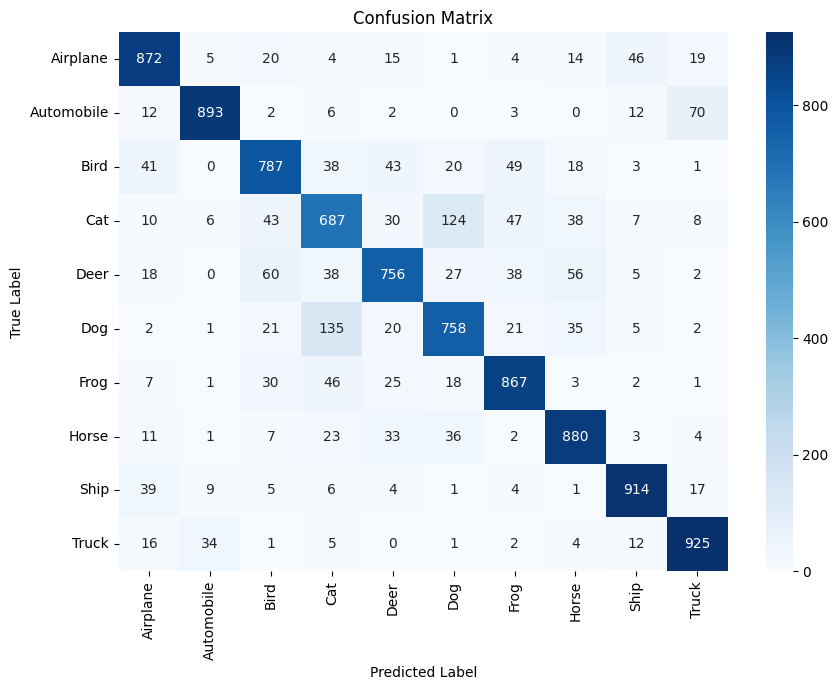

In [13]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


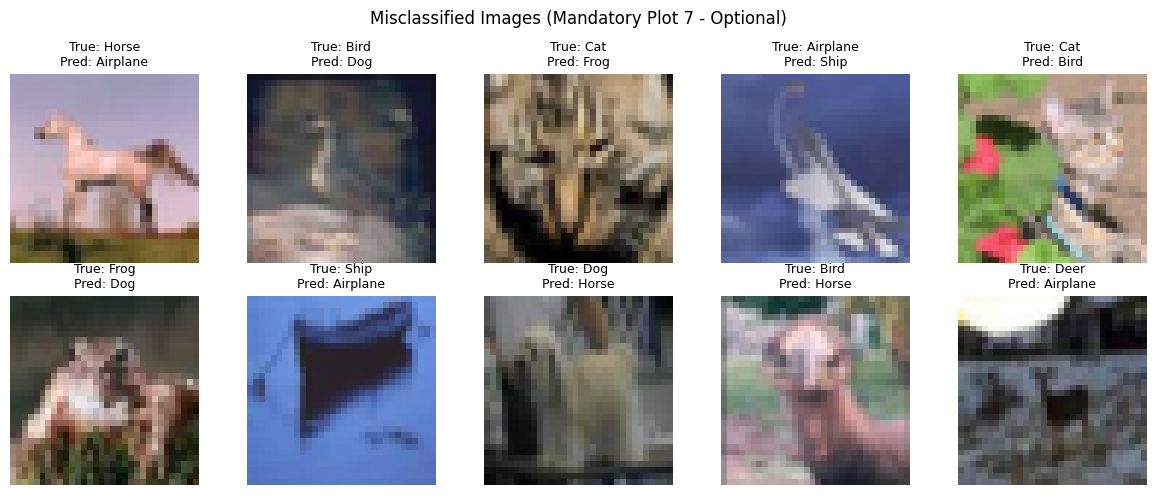

In [14]:
# Misclassified images (optional)
misclassified_idx = np.where(y_pred != y_true)[0]
sample_idx = np.random.choice(misclassified_idx, size=min(10, len(misclassified_idx)), replace=False)

plt.figure(figsize=(12, 5))
for i, idx in enumerate(sample_idx):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx])
    plt.title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}", fontsize=9)
    plt.axis('off')
plt.suptitle("Misclassified Images (Mandatory Plot 7 - Optional)")
plt.tight_layout()
plt.savefig('misclassified_images.png', dpi=150, bbox_inches='tight')
plt.show()


## Filling in the Results Tables (Section 18 of the manual)

In [15]:
print("18.1 Performance Metrics")
print("-" * 40)
print(f"Training Accuracy : {full_acc[-1]:.4f}")
print(f"Testing Accuracy  : {acc:.4f}")
print(f"Precision         : {prec:.4f}")
print(f"Recall            : {rec:.4f}")
print(f"F1-score          : {f1:.4f}")
print(f"Training Time     : {training_time_initial + training_time_finetune:.2f} sec")
print(f"Total Parameters  : {model.count_params():,}")


18.1 Performance Metrics
----------------------------------------
Training Accuracy : 0.9677
Testing Accuracy  : 0.8339
Precision         : 0.8336
Recall            : 0.8339
F1-score          : 0.8334
Training Time     : 1062.42 sec
Total Parameters  : 14,848,586


In [16]:
def build_lenet5(input_shape=(32, 32, 3), num_classes=10):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(6, kernel_size=5, activation='tanh', padding='same'),
        layers.AveragePooling2D(pool_size=2),
        layers.Conv2D(16, kernel_size=5, activation='tanh'),
        layers.AveragePooling2D(pool_size=2),
        layers.Flatten(),
        layers.Dense(120, activation='tanh'),
        layers.Dense(84, activation='tanh'),
        layers.Dense(num_classes, activation='softmax')
    ], name='LeNet5')
    return model

lenet5 = build_lenet5()
lenet5.compile(optimizer=optimizers.Adam(learning_rate=0.001),
                loss='categorical_crossentropy', metrics=['accuracy'])
lenet5.summary()

t0 = time.time()
lenet5_history = lenet5.fit(x_train, y_train_cat, validation_data=(x_test, y_test_cat),
                             epochs=15, batch_size=32, verbose=1)
lenet5_time = time.time() - t0

lenet5_loss, lenet5_acc = lenet5.evaluate(x_test, y_test_cat, verbose=0)
lenet5_params = lenet5.count_params()
print(f"\nLeNet-5 -> Test Accuracy: {lenet5_acc:.4f} | Params: {lenet5_params:,} | Time: {lenet5_time:.1f}s")


Model: "LeNet5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 16, 16, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 12, 12, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 6, 6, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 120)            │        69,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83,126 (324.71 KB)

 Trainable params: 83,126 (324.71 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.3768 - loss: 1.7713 - val_accuracy: 0.4305 - val_loss: 1.6294
Epoch 2/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.4628 - loss: 1.5204 - val_accuracy: 0.4862 - val_loss: 1.4632
Epoch 3/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5079 - loss: 1.3904 - val_accuracy: 0.5034 - val_loss: 1.4170
Epoch 4/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5364 - loss: 1.3114 - val_accuracy: 0.5117 - val_loss: 1.3846
Epoch 5/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5584 - loss: 1.2509 - val_accuracy: 0.5127 - val_loss: 1.3723
Epoch 6/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5722 - loss: 1.2029 - val_accuracy: 0.5152 - val_loss: 1.3730
Epoch 7/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5879 - loss: 1.1631 - val_accuracy: 0.5193 - val_loss: 1.3771
Epoch 8/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6022 - loss: 1.1292 -

In [17]:
def build_alexnet_cifar(input_shape=(32, 32, 3), num_classes=10):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(64, kernel_size=3, strides=1, padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(192, kernel_size=3, padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(384, kernel_size=3, padding='same', activation='relu'),
        layers.Conv2D(256, kernel_size=3, padding='same', activation='relu'),
        layers.Conv2D(256, kernel_size=3, padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=2),
        layers.Flatten(),
        layers.Dense(1024, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ], name='AlexNet_CIFAR')
    return model

alexnet = build_alexnet_cifar()
alexnet.compile(optimizer=optimizers.Adam(learning_rate=0.001),
                 loss='categorical_crossentropy', metrics=['accuracy'])
alexnet.summary()

t0 = time.time()
alexnet_history = alexnet.fit(x_train, y_train_cat, validation_data=(x_test, y_test_cat),
                               epochs=15, batch_size=32, verbose=1)
alexnet_time = time.time() - t0

alexnet_loss, alexnet_acc = alexnet.evaluate(x_test, y_test_cat, verbose=0)
alexnet_params = alexnet.count_params()
print(f"\nAlexNet -> Test Accuracy: {alexnet_acc:.4f} | Params: {alexnet_params:,} | Time: {alexnet_time:.1f}s")


Model: "AlexNet_CIFAR"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 192)    │       110,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 192)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 384)      │       663,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 256)      │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1024)           │     4,195,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,976,842 (26.61 MB)

 Trainable params: 6,976,842 (26.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 33s 17ms/step - accuracy: 0.3350 - loss: 1.7700 - val_accuracy: 0.5145 - val_loss: 1.3288
Epoch 2/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.5358 - loss: 1.2951 - val_accuracy: 0.5889 - val_loss: 1.1584
Epoch 3/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.6105 - loss: 1.1058 - val_accuracy: 0.6351 - val_loss: 1.0277
Epoch 4/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.6567 - loss: 0.9876 - val_accuracy: 0.6552 - val_loss: 0.9790
Epoch 5/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.6861 - loss: 0.9002 - val_accuracy: 0.6690 - val_loss: 0.9426
Epoch 6/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.7127 - loss: 0.8292 - val_accuracy: 0.6795 - val_loss: 0.9279
Epoch 7/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.7303 - loss: 0.7765 - val_accuracy: 0.6830 - val_loss: 0.9493
Epoch 8/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.7476 -

In [18]:
def inception_module(x, f_1x1, f_3x3_reduce, f_3x3, f_5x5_reduce, f_5x5, f_pool_proj, name):
    # Branch 1: 1x1 conv
    branch1 = layers.Conv2D(f_1x1, 1, padding='same', activation='relu')(x)

    # Branch 2: 1x1 conv (bottleneck) -> 3x3 conv
    branch2 = layers.Conv2D(f_3x3_reduce, 1, padding='same', activation='relu')(x)
    branch2 = layers.Conv2D(f_3x3, 3, padding='same', activation='relu')(branch2)

    # Branch 3: 1x1 conv (bottleneck) -> 5x5 conv
    branch3 = layers.Conv2D(f_5x5_reduce, 1, padding='same', activation='relu')(x)
    branch3 = layers.Conv2D(f_5x5, 5, padding='same', activation='relu')(branch3)

    # Branch 4: 3x3 max pool -> 1x1 conv (projection)
    branch4 = layers.MaxPooling2D(3, strides=1, padding='same')(x)
    branch4 = layers.Conv2D(f_pool_proj, 1, padding='same', activation='relu')(branch4)

    # Concatenate all branches along the channel axis
    return layers.Concatenate(name=name)([branch1, branch2, branch3, branch4])


def build_googlenet_cifar(input_shape=(32, 32, 3), num_classes=10):
    inputs = keras.Input(shape=input_shape)

    x = layers.Conv2D(64, 3, padding='same', activation='relu')(inputs)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(64, 1, padding='same', activation='relu')(x)
    x = layers.Conv2D(192, 3, padding='same', activation='relu')(x)
    x = layers.MaxPooling2D(2)(x)

    # Inception module 1
    x = inception_module(x, f_1x1=64, f_3x3_reduce=96, f_3x3=128,
                          f_5x5_reduce=16, f_5x5=32, f_pool_proj=32,
                          name='inception_1')

    x = layers.MaxPooling2D(2)(x)

    # Inception module 2
    x = inception_module(x, f_1x1=128, f_3x3_reduce=128, f_3x3=192,
                          f_5x5_reduce=32, f_5x5=96, f_pool_proj=64,
                          name='inception_2')

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return keras.Model(inputs, outputs, name='GoogleNet_CIFAR')

googlenet = build_googlenet_cifar()
googlenet.compile(optimizer=optimizers.Adam(learning_rate=0.001),
                   loss='categorical_crossentropy', metrics=['accuracy'])
googlenet.summary()

t0 = time.time()
googlenet_history = googlenet.fit(x_train, y_train_cat, validation_data=(x_test, y_test_cat),
                                   epochs=15, batch_size=32, verbose=1)
googlenet_time = time.time() - t0

googlenet_loss, googlenet_acc = googlenet.evaluate(x_test, y_test_cat, verbose=0)
googlenet_params = googlenet.count_params()
print(f"\nGoogleNet -> Test Accuracy: {googlenet_acc:.4f} | Params: {googlenet_params:,} | Time: {googlenet_time:.1f}s")


Model: "GoogleNet_CIFAR"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_18      │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │      1,792 │ input_layer_18[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 16, 16,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │      4,160 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │    110,784 │ conv2d_8[0][0]    │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 8, 8, 192) │          0 │ conv2d_9[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 8, 8, 96)  │     18,528 │ max_pooling2d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 8, 8, 16)  │      3,088 │ max_pooling2d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 8, 8, 192) │          0 │ max_pooling2d_4[… │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 8, 8, 64)  │     12,352 │ max_pooling2d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 8, 8, 128) │    110,720 │ conv2d_11[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 8, 8, 32)  │     12,832 │ conv2d_13[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 8, 8, 32)  │      6,176 │ max_pooling2d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_1         │ (None, 8, 8, 256) │          0 │ conv2d_10[0][0],  │
│ (Concatenate)       │                   │            │ conv2d_12[0][0],  │
│                     │                   │            │ conv2d_14[0][0],  │
│                     │                   │            │ conv2d_15[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 4, 4, 256) │          0 │ inception_1[0][0] │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 4, 4, 128) │     32,896 │ max_pooling2d_6[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 4, 4, 32)  │      8,224 │ max_pooling2d_6[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 4, 4, 256) │          0 │ max_pooling2d_6[… │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 4, 4, 128) │     32,896 │ max_pooling2d_6[

 Total params: 673,978 (2.57 MB)

 Trainable params: 673,978 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 32s 14ms/step - accuracy: 0.4065 - loss: 1.5975 - val_accuracy: 0.5593 - val_loss: 1.2046
Epoch 2/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.6035 - loss: 1.1034 - val_accuracy: 0.6503 - val_loss: 0.9694
Epoch 3/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.6786 - loss: 0.9019 - val_accuracy: 0.6788 - val_loss: 0.9043
Epoch 4/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.7240 - loss: 0.7742 - val_accuracy: 0.7258 - val_loss: 0.7833
Epoch 5/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.7627 - loss: 0.6746 - val_accuracy: 0.7063 - val_loss: 0.8459
Epoch 6/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.7926 - loss: 0.5931 - val_accuracy: 0.7351 - val_loss: 0.7798
Epoch 7/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8131 - loss: 0.5253 - val_accuracy: 0.7284 - val_loss: 0.8494
Epoch 8/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8318 - loss: 

In [19]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

def build_resnet50_transfer(base_trainable=False, dense_units=256, dropout=0.3, img_size=64):
    base = ResNet50(weights='imagenet', include_top=False, input_shape=(img_size, img_size, 3))
    base.trainable = base_trainable

    inputs = keras.Input(shape=(32, 32, 3))         # expects [0,1]-normalized input
    x = layers.Rescaling(255.0)(inputs)               # undo /255 -> back to [0,255]
    x = layers.Resizing(img_size, img_size)(x)
    x = layers.Lambda(resnet_preprocess)(x)            # ResNet50-specific preprocessing
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation='relu')(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(10, activation='softmax')(x)

    return keras.Model(inputs, outputs), base

resnet_model, resnet_base = build_resnet50_transfer(base_trainable=False)
resnet_model.compile(optimizer=optimizers.Adam(learning_rate=0.001),
                      loss='categorical_crossentropy', metrics=['accuracy'])

t0 = time.time()
resnet_history = resnet_model.fit(x_train, y_train_cat, validation_data=(x_test, y_test_cat),
                                   epochs=15, batch_size=32, verbose=1)
resnet_time_initial = time.time() - t0

pre_ft_loss, pre_ft_acc_resnet = resnet_model.evaluate(x_test, y_test_cat, verbose=0)
print(f"ResNet50 test accuracy BEFORE fine-tuning: {pre_ft_acc_resnet:.4f}")


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 47s 22ms/step - accuracy: 0.7139 - loss: 0.8663 - val_accuracy: 0.7628 - val_loss: 0.6909
Epoch 2/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 24s 15ms/step - accuracy: 0.7687 - loss: 0.6677 - val_accuracy: 0.7718 - val_loss: 0.6556
Epoch 3/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 41s 15ms/step - accuracy: 0.7943 - loss: 0.5910 - val_accuracy: 0.7833 - val_loss: 0.6506
Epoch 4/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 24s 15ms/step - accuracy: 0.8102 - loss: 0.5375 - val_accuracy: 0.7802 - val_loss: 0.6807
Epoch 5/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.8274 - loss: 0.4915 - val_accuracy: 0.7857 - val_loss: 0.6740
Epoch 6/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 24s 15ms/step - accuracy: 0.8410 - loss: 0.4468 - val_accuracy: 0.7824 - val_loss: 0.6958
Epoch 7/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 25s 16ms/step - accuracy: 0.8518 - loss: 0.4170 - val_accuracy: 0.7855 - val_loss: 0.7199
Epoch 8/15
1563/1563 ━━━━

In [20]:
# Fine-tune ResNet50: unfreeze the last residual block (conv5_block*)
resnet_base.trainable = True
for layer in resnet_base.layers:
    layer.trainable = layer.name.startswith('conv5_block')

resnet_model.compile(optimizer=optimizers.Adam(learning_rate=1e-5),
                      loss='categorical_crossentropy', metrics=['accuracy'])

t0 = time.time()
resnet_ft_history = resnet_model.fit(x_train, y_train_cat, validation_data=(x_test, y_test_cat),
                                      epochs=8, batch_size=32, verbose=1)
resnet_time_finetune = time.time() - t0

resnet_loss, resnet_acc = resnet_model.evaluate(x_test, y_test_cat, verbose=0)
resnet_params = resnet_model.count_params()
print(f"ResNet50 test accuracy AFTER fine-tuning: {resnet_acc:.4f}")
print(f"Total ResNet50 training time: {resnet_time_initial + resnet_time_finetune:.1f}s")
print(f"Total ResNet50 parameters: {resnet_params:,}")

resnet_y_pred = np.argmax(resnet_model.predict(x_test, batch_size=64, verbose=0), axis=1)
print("\nResNet50 Classification Report:\n")
print(classification_report(y_true, resnet_y_pred, target_names=class_names))


Epoch 1/8
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 72s 33ms/step - accuracy: 0.7817 - loss: 0.8230 - val_accuracy: 0.7710 - val_loss: 0.9989
Epoch 2/8
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 36s 23ms/step - accuracy: 0.8885 - loss: 0.3167 - val_accuracy: 0.7844 - val_loss: 0.9601
Epoch 3/8
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 41s 23ms/step - accuracy: 0.9357 - loss: 0.1816 - val_accuracy: 0.7916 - val_loss: 0.9795
Epoch 4/8
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 36s 23ms/step - accuracy: 0.9629 - loss: 0.1136 - val_accuracy: 0.7975 - val_loss: 0.9947
Epoch 5/8
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 36s 23ms/step - accuracy: 0.9756 - loss: 0.0780 - val_accuracy: 0.8013 - val_loss: 1.0287
Epoch 6/8
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 36s 23ms/step - accuracy: 0.9845 - loss: 0.0543 - val_accuracy: 0.8043 - val_loss: 1.0635
Epoch 7/8
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 36s 23ms/step - accuracy: 0.9874 - loss: 0.0425 - val_accuracy: 0.8066 - val_loss: 1.1026
Epoch 8/8
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 37s 24ms/step - accuracy: 0.9904 - loss: 0

In [21]:
OPT_EPOCHS = 10

# Adam run
adam_model, _ = build_transfer_model(base_trainable=False)
adam_model.compile(optimizer=optimizers.Adam(learning_rate=0.001),
                    loss='categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
adam_hist = adam_model.fit(x_train, y_train_cat, validation_data=(x_test, y_test_cat),
                            epochs=OPT_EPOCHS, batch_size=32, verbose=1)
adam_time = time.time() - t0

# SGD run (with momentum, standard practice)
sgd_model, _ = build_transfer_model(base_trainable=False)
sgd_model.compile(optimizer=optimizers.SGD(learning_rate=0.001, momentum=0.9),
                   loss='categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
sgd_hist = sgd_model.fit(x_train, y_train_cat, validation_data=(x_test, y_test_cat),
                          epochs=OPT_EPOCHS, batch_size=32, verbose=1)
sgd_time = time.time() - t0

print(f"Adam -> final val_accuracy: {adam_hist.history['val_accuracy'][-1]:.4f} | time: {adam_time:.1f}s")
print(f"SGD  -> final val_accuracy: {sgd_hist.history['val_accuracy'][-1]:.4f} | time: {sgd_time:.1f}s")


Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 44s 27ms/step - accuracy: 0.6521 - loss: 1.2660 - val_accuracy: 0.7350 - val_loss: 0.7855
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 38s 24ms/step - accuracy: 0.7421 - loss: 0.7598 - val_accuracy: 0.7459 - val_loss: 0.7498
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 38s 24ms/step - accuracy: 0.7647 - loss: 0.6850 - val_accuracy: 0.7561 - val_loss: 0.7339
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 38s 24ms/step - accuracy: 0.7798 - loss: 0.6384 - val_accuracy: 0.7545 - val_loss: 0.7499
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 38s 24ms/step - accuracy: 0.7927 - loss: 0.5998 - val_accuracy: 0.7598 - val_loss: 0.7575
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 38s 24ms/step - accuracy: 0.8049 - loss: 0.5662 - val_accuracy: 0.7563 - val_loss: 0.7849
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 38s 24ms/step - accuracy: 0.8149 - loss: 0.5325 - val_accuracy: 0.7584 - val_loss: 0.7994
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 38s 24ms/step - accuracy: 0.8243 -

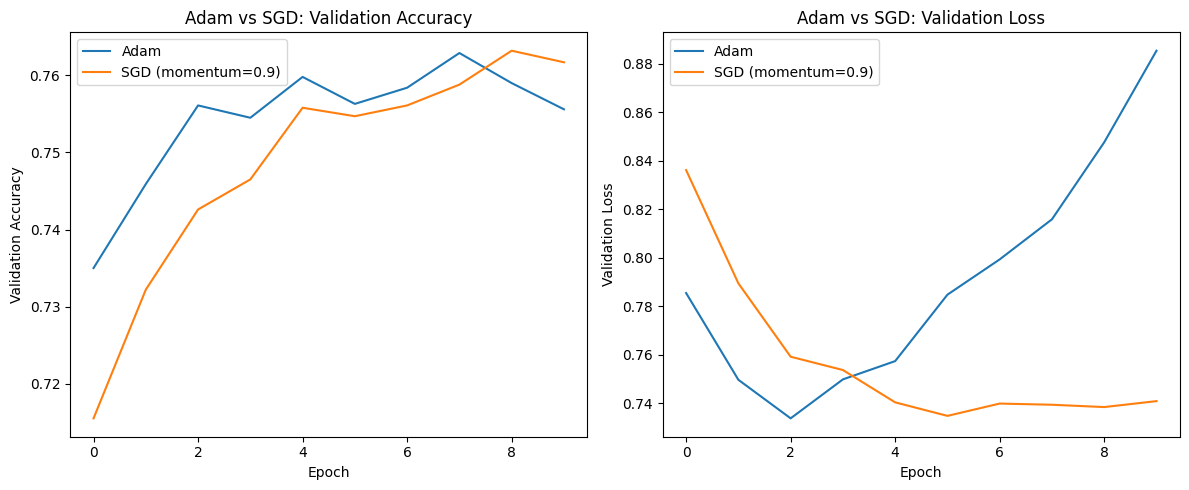

In [22]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(adam_hist.history['val_accuracy'], label='Adam')
plt.plot(sgd_hist.history['val_accuracy'], label='SGD (momentum=0.9)')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.title('Adam vs SGD: Validation Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(adam_hist.history['val_loss'], label='Adam')
plt.plot(sgd_hist.history['val_loss'], label='SGD (momentum=0.9)')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.title('Adam vs SGD: Validation Loss')
plt.legend()

plt.tight_layout()
plt.savefig('adam_vs_sgd.png', dpi=150, bbox_inches='tight')
plt.show()


In [23]:
final_comparison = pd.DataFrame({
    'Model': ['LeNet-5', 'AlexNet (CIFAR adapted)', 'GoogleNet (CIFAR adapted)',
              'VGG16 (transfer)', 'ResNet50 (transfer)'],
    'Parameters': [f"{lenet5_params:,}", f"{alexnet_params:,}", f"{googlenet_params:,}",
                   f"{model.count_params():,}", f"{resnet_params:,}"],
    'Test Accuracy (%)': [round(lenet5_acc * 100, 2), round(alexnet_acc * 100, 2),
                           round(googlenet_acc * 100, 2),
                           round(acc * 100, 2), round(resnet_acc * 100, 2)],
    'Training Time (s)': [round(lenet5_time, 1), round(alexnet_time, 1), round(googlenet_time, 1),
                           round(training_time_initial + training_time_finetune, 1),
                           round(resnet_time_initial + resnet_time_finetune, 1)]
})
print(final_comparison.to_string(index=False))
final_comparison


                    Model Parameters  Test Accuracy (%)  Training Time (s)
                  LeNet-5     83,126              51.08               98.2
  AlexNet (CIFAR adapted)  6,976,842              71.36              297.6
GoogleNet (CIFAR adapted)    673,978              75.31              211.8
         VGG16 (transfer) 14,848,586              83.39             1062.4
      ResNet50 (transfer) 24,114,826              81.39              729.9


,Model,Parameters,Test Accuracy (%),Training Time (s)
0,LeNet-5,"83,126",51.08,98.2
1,AlexNet (CIFAR adapted),"6,976,842",71.36,297.6
2,GoogleNet (CIFAR adapted),"673,978",75.31,211.8
3,VGG16 (transfer),"14,848,586",83.39,1062.4
4,ResNet50 (transfer),"24,114,826",81.39,729.9
